# The page to the city head, an AI-free written business case: what goes on one page?

**Week 4, Tuesday, chapter 9, the case's fourth chapter.** It applies the AI-free written
business case (concept notebook 07) and the one-slide answer: claim, evidence, caveat, action
(concept notebook 01). Notebook 07 found that Ramesh's page (invented) carried the slide's
four parts as four sentences in 108 words, where the draft ran nine lines, 13 numbers and four
method words. Notebook 08 sized the evening peak at about 5,000 to 5,700 drivers.

**Open this notebook after your page is handed in.** The page is written by hand, in 35
minutes, with laptops closed, because it shows your own thinking. This notebook then checks
the numbers the brief gave you against the case's own table and runs notebook 07's rules on
a typed copy of your page.

**The ticket.** Uber, Hyderabad, the peak-hour earnings guarantee. The city head reads one
page, alone, before Thursday's city review, with the driver-operations lead, the marketing
lead and the finance partner reading over a shoulder.

> *Illustrative case: the company is real, the situation and the data are synthetic, built for this class.*

**Who needs the answer.** The city head, who signs or refuses the test on the strength of the
page; a page that misquotes its number hands the finance partner a reason to set it aside.

**The metric at stake.** Gross bookings per peak online hour, Rs 314 to Rs 260, and the
saving, Rs 58 lakh to Rs 92.7 lakh over six weeks.

**The questions on the way.**

1. Is the page's number right, counted from the case's table?
2. Where does the saving range come from, and what does each end assume?
3. Which opening does the city head act on?
4. Does your page pass the rules?

In [1]:
import textwrap
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.figsize": (9, 3.8), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
INK, VIOLET, LILAC, PALE, ROSE, AMBER = "#1A0F5C", "#5B3FD6", "#B9AEF0", "#EEEAFB", "#D63A6A", "#C98A00"

def check(name, ok):
    print(("PASS " if ok else "FAIL ") + name)

weeks = pd.read_csv("../data/C2_W04_D02_twelve_weeks_STUDENT.csv")   # the city, week by week
check("six weeks before the launch and six after", (weeks.window.value_counts() == 6).all())
print(weeks[["week_start", "window", "peak_online_hours", "peak_trips", "peak_bookings_rs"]].to_string(index=False))

PASS six weeks before the launch and six after
week_start window  peak_online_hours  peak_trips  peak_bookings_rs
2026-07-20 before              19571       36752           6064080
2026-07-27 before              19398       37095           6120675
2026-08-03 before              19720       37183           6135195
2026-08-10 before              19513       37452           6179580
2026-08-17 before              19578       37688           6218520
2026-08-24 before              20220       38030           6274950
2026-08-31  after              23816       39121           6454965
2026-09-07  after              24932       39547           6525255
2026-09-14  after              24871       39056           6444240
2026-09-21  after              24643       38313           6321645
2026-09-28  after              24247       37755           6229575
2026-10-05  after              23791       37108           6122820


## Is the page's number right, counted from the case's table?

The brief gave Rs 314 to Rs 260 of fares per peak online hour. A number on a page read alone
has to survive a reader who recounts it.

**Predict before you run.** Which reading of the twelve weeks gives the page's number?

a) The last week after the launch against the first week before it
b) Each window's bookings summed, over its online hours summed
c) The best week before against the worst week after
d) The two windows' busiest weeks, side by side

summed by window: Rs 313.5 before, Rs 260.4 after
the first and last weeks alone: Rs 309.85 and Rs 257.36
PASS summed by window: Rs 313.5 and Rs 260.4, printed Rs 314 and Rs 260
PASS the six weekly rates, averaged, land within a rupee of the sums
PASS a second route, the fare times trips per hour, agrees


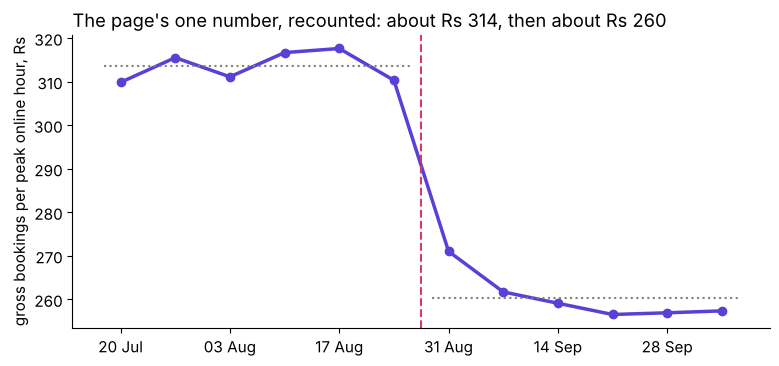

In [2]:
w = weeks.groupby("window")[["peak_online_hours", "peak_trips", "peak_bookings_rs"]].sum().loc[["before", "after"]]
per_hour = w.peak_bookings_rs / w.peak_online_hours                  # each window's rupees over its hours
ends = weeks.rs_per_hour.iloc[[0, -1]].tolist()                      # the first week and the last
mean_of_weeks = weeks.groupby("window").rs_per_hour.mean().loc[["before", "after"]]
fare_route = (w.peak_bookings_rs / w.peak_trips) * (w.peak_trips / w.peak_online_hours)
print(f"summed by window: Rs {per_hour['before']:.1f} before, Rs {per_hour['after']:.1f} after")
print(f"the first and last weeks alone: Rs {ends[0]:.2f} and Rs {ends[1]:.2f}")
check("summed by window: Rs 313.5 and Rs 260.4, printed Rs 314 and Rs 260",
      per_hour.round(1).tolist() == [313.5, 260.4])
check("the six weekly rates, averaged, land within a rupee of the sums", ((mean_of_weeks - per_hour).abs() < 1).all())
check("a second route, the fare times trips per hour, agrees", ((fare_route - per_hour).abs() < 1e-9).all())

x = range(len(weeks))
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(x, weeks.rs_per_hour, color=VIOLET, lw=2.5, marker="o")
ax.hlines(per_hour["before"], -0.3, 5.3, color="gray", ls=":")
ax.hlines(per_hour["after"], 5.7, 11.3, color="gray", ls=":")
ax.axvline(5.5, color=ROSE, ls="--")
ax.set_xticks(list(x)[::2], pd.to_datetime(weeks.week_start).dt.strftime("%d %b")[::2])
ax.set_ylabel("gross bookings per peak online hour, Rs")
ax.set_title("The page's one number, recounted: about Rs 314, then about Rs 260", loc="left")
plt.show()

**What happened.** The answer is b: Rs 313.5 before and Rs 260.4 after, printed Rs 314 and Rs
260, and two other routes agree. The first and last weeks alone would print other numbers, so
the page says which windows it compares: the six weeks either side of 31 August 2026.

## Where does the saving range come from, and what does each end assume?

Monday's figure, typed here: Rs 1.16 crore (115.9 lakh, since 1 crore is 100 lakh) of the Rs
1.9 crore top-up went to driver-weeks that accepted fewer than half the requests offered to
them. The redesign stops paying it, except where those drivers start accepting and qualify.

**Predict before you run.** If a fifth of that money is still paid, against a half, the saving
is:

a) Smaller
b) Larger
c) The same, since the top-up is the same
d) Nothing, since drivers who accept are still paid

a half still paid     58.0
a fifth still paid    92.7
PASS a half still paid saves Rs 58 lakh
PASS a fifth still paid saves Rs 92.7 lakh


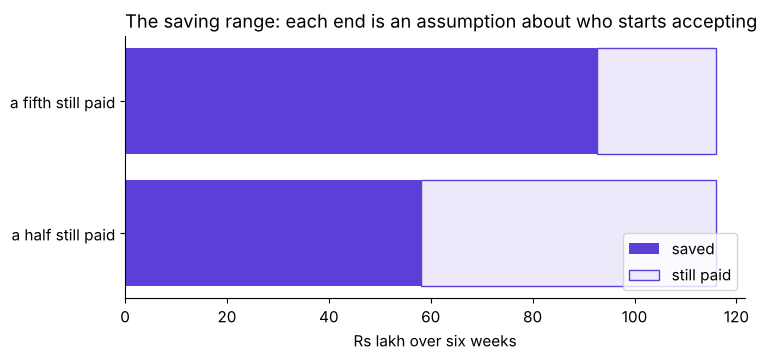

In [3]:
idle_lakh = 115.9                                     # Monday's top-up to low-acceptance driver-weeks
still_paid = pd.Series({"a half still paid": 0.5, "a fifth still paid": 0.2})
saved = (idle_lakh * (1 - still_paid)).round(1)
print(saved.rename("saved over six weeks, Rs lakh").to_string())
check("a half still paid saves Rs 58 lakh", saved.iloc[0] == 58.0)
check("a fifth still paid saves Rs 92.7 lakh", saved.iloc[1] == 92.7)

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(still_paid.index, saved, color=VIOLET, label="saved")
ax.barh(still_paid.index, idle_lakh - saved, left=saved, color=PALE, edgecolor=VIOLET, label="still paid")
ax.set_xlabel("Rs lakh over six weeks")
ax.set_title("The saving range: each end is an assumption about who starts accepting", loc="left")
ax.legend(loc="lower right")
plt.show()

**What happened.** The answer is b: Rs 92.7 lakh if a fifth is still paid, Rs 58 lakh if a half
is. The page says the range with the assumption behind it, in its action sentence, so the
finance partner reads the same arithmetic.

## Which opening does the city head act on?

Two openings from the interview room's first transcript. A page is read alone, so its first
sentence has to name the decision and what to do about it. The cell writes that test as a
function and runs notebook 07's page rules, restated here, on Ramesh's page (invented) to
prove them.

**Predict before you run.** Which opening gives the city head something to do?

a) The weak one, since it reports every number first
b) The hire-grade one, since it names the decision and recommends a test
c) Both, since each mentions paying per trip
d) Neither, since an opening should be a question

the weak opening acts: False    the hire-grade opening acts: True
PASS only the hire-grade opening names the decision
PASS the page rules pass Ramesh's page (invented)
The scheme is paying for online hours that carry no trips, so I recommend testing a change before the city pays for another six weeks.
An hour online at peak brought in Rs 260 of fares in the six weeks after the launch, down from Rs 314, at the same Rs 165 fare.
The monsoon ended inside the same six weeks and last year's weeks are not in the data, so part of the fall may be the season.
Test paying per completed peak trip, with an acceptance floor, on half the drivers for six weeks; city-wide the change saves Rs 58 lakh to Rs 92.7 lakh, and the city head signs.
PASS a page built from the case's own numbers passes every rule


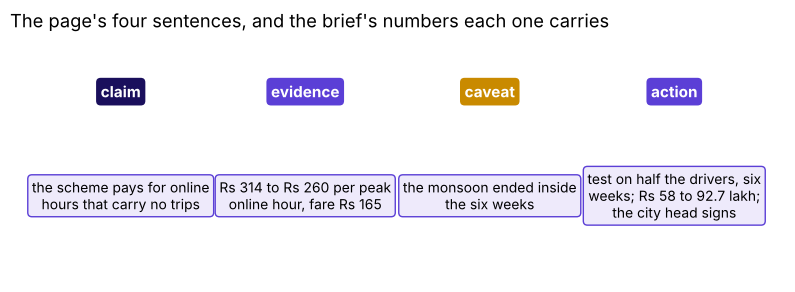

In [4]:
weak = "So I looked at the dashboard."
hire = ("You are deciding whether to keep, end or change the guarantee, so my answer first: the scheme is paying "
        "for online hours that carry no trips, and I recommend testing a change before the city pays for another six weeks.")

def acts(sentence):
    """A first sentence a reader can act on names the decision and what to do."""
    return any(word in sentence.lower() for word in ("recommend", "keep", "end ", "change", "test"))

METHOD = ["denominator", "index", "guardrail", "north star"]

def page_check(text):
    """Notebook 07's rules, restated: what a reader checks in two minutes."""
    sentences = [s for s in text.splitlines() if s.strip() and not s.startswith("VERSION")]
    return {"opens on a claim with its reason": "because" in sentences[0] or " so " in sentences[0],
            "no method words": not any(w in text.lower() for w in METHOD),
            "the action names a cost and who signs": "Rs" in sentences[-1] and "signs" in sentences[-1],
            "one page, 250 words or fewer": len(text.split()) <= 250,
            "four to six sentences": 4 <= len(sentences) <= 6}

ramesh = open("../data/C2_W04_D02_kirana_page_STUDENT.txt", encoding="utf-8").read().split("=====")[1]
print("the weak opening acts:", acts(weak), "   the hire-grade opening acts:", acts(hire))
check("only the hire-grade opening names the decision", acts(hire) and not acts(weak))
check("the page rules pass Ramesh's page (invented)", all(page_check(ramesh).values()))

city_page = "\n".join([                                        # the page's four lines, on the case's own numbers
    "The scheme is paying for online hours that carry no trips, so I recommend testing a change before the city pays for another six weeks.",
    f"An hour online at peak brought in Rs {per_hour['after']:.0f} of fares in the six weeks after the launch, down from Rs {per_hour['before']:.0f}, at the same Rs 165 fare.",
    "The monsoon ended inside the same six weeks and last year's weeks are not in the data, so part of the fall may be the season.",
    f"Test paying per completed peak trip, with an acceptance floor, on half the drivers for six weeks; city-wide the change saves Rs {saved.iloc[0]:.0f} lakh to Rs {saved.iloc[1]} lakh, and the city head signs."])
print(city_page)
check("a page built from the case's own numbers passes every rule", all(page_check(city_page).values()))

fig, ax = plt.subplots(figsize=(10, 3.2))
parts = [("claim", "the scheme pays for online\nhours that carry no trips"),
         ("evidence", "Rs 314 to Rs 260 per peak\nonline hour, fare Rs 165"),
         ("caveat", "the monsoon ended inside\nthe six weeks"),
         ("action", "test on half the drivers, six\nweeks; Rs 58 to 92.7 lakh;\nthe city head signs")]
for i, (part, words) in enumerate(parts):
    ax.text(i, 0.75, part, ha="center", weight="bold", color="white",
            bbox=dict(boxstyle="round", fc=[INK, VIOLET, AMBER, VIOLET][i], ec="none"))
    ax.text(i, 0.35, words, ha="center", va="center", fontsize=10, bbox=dict(boxstyle="round", fc=PALE, ec=VIOLET))
ax.set_xlim(-0.6, 3.6)
ax.set_ylim(0, 1)
ax.axis("off")
ax.set_title("The page's four sentences, and the brief's numbers each one carries", loc="left")
plt.show()

**What happened.** The answer is b. The weak opening reports what the analyst looked at; the
hire-grade one names the decision, the claim and the recommendation in one sentence. The four
lines printed above are the page on the case's own numbers, each recounted in this notebook,
and they pass every rule; the picture is the same page as its skeleton, with the brief's
numbers in the sentence that carries each.

**Your turn.** Type the page you handed in into `my_page`, one sentence a line, and run the
rules on it. The rules check the shape; your trainer reads the argument. Type the lines into
the empty cell below and run them:

```python
my_page = """
___
""".strip()
mine = page_check(my_page)
print(pd.Series(mine).to_string())
check("my first sentence names the decision", acts(my_page.splitlines()[0]))
check("my page passes every rule", all(mine.values()))
```

**The answers, one line each.**

1. Each window's bookings over its online hours give Rs 313.5 and Rs 260.4, printed Rs 314 and
   Rs 260; two other routes agree.
2. The range is Rs 1.16 crore times one less the share still paid: a half gives Rs 58 lakh, a
   fifth Rs 92.7 lakh.
3. The hire-grade opening names the decision and recommends a test; the weak one reports what
   was looked at.
4. Your page passes when its first sentence names the decision and every rule holds.

### What will an interviewer ask about this, and what does a strong answer do?

**[S] Present a recommendation to a non-technical stakeholder in two minutes.** The page,
spoken: the decision and the claim first, one number with what it is divided by and its
window, the caveat, then the action with its cost, its window and who signs.

**The AI-company variant.** The same page goes to a coding assistant's head of product: the
claim (judge the team on suggested code still in the file seven days after acceptance), one
number (32 percent of suggestions accepted, about 26 percent of those shown still there a
week later, invented), the caveat (customers see acceptance, so it stays in the sales deck as
a leading input), and the action (hold out a share of users for a quarter, keep whichever
number tracks seat renewals, and the head of product signs).